# PlonkNet-10: Baseline Training
### Evan André Santana Pacheco A01769493
### TC3009C.601

Country-level geolocation of Street View images with a pretrained CNN

GeoLocation – Geoguessr Images (50K) (Kaggle)
https://www.kaggle.com/datasets/ubitquitin/geolocation-geoguessr-images-50k

This notebook trains the first model (baseline): a ResNet50 pretrained on ImageNet, frozen, with a new linear head of 10 outputs, one per country. Because the backbone is frozen and there is no augmentation, the 2,048 features of every image are computed once and cached, and only the head is trained on them; this also makes the baseline possible on CPU. The model is evaluated on validation (per-country F1, easy vs. hard groups, confusion matrix and calibration) and only once on test, and its weights are exported for the prediction notebook.

**Input → Output**
`plonknet10_256.zip` and `classes.json` → `plonknet10_baseline_v1.pt` (weights + configuration), `features_resnet50_224x512.pt` (cached features), `history_baseline_v1.csv`, `results_baseline_v1.csv` and the evaluation figures

**References**
- He, K., Zhang, X., Ren, S., & Sun, J. (2016). *Deep Residual Learning for Image Recognition*. CVPR. https://arxiv.org/abs/1512.03385
- Pretrained weights (`IMAGENET1K_V2`), torchvision documentation: https://pytorch.org/vision/stable/models/generated/torchvision.models.resnet50.html

## Design decisions
* Framework: PyTorch and torchvision are chosen for native pretrained model support, direct folder parsing via ImageFolder, and out-of-the-box Grad-CAM tool compatibility.

* Backbone: A ResNet50 pretrained on ImageNet is used because training from scratch with ~9,700 images is unviable, leveraging transfer learning to inherit spatial feature extractors for roads, vegetation, and structures.

* Training Strategy: A frozen backbone with only the final linear head trained, establishing a fast, low-overfitting baseline before fine-tuning later.

* Computation & Feature Caching: Since the backbone is frozen and data has no augmentation, 2,048-dimensional features are computed once and cached, drastically accelerating training and enabling a CPU-compatible baseline.

* Input Size: Set to
224×512 to preserve the panoramic aspect ratio (~2.3) of street views without discarding side information, fully supported by ResNet's global average pooling.

* Normalization: Standard ImageNet per-channel mean and standard deviation are applied to match the exact distribution the backbone was trained on.

* Data Augmentation: None used in the baseline to isolate variables. We will revisit options for a second iteration.

* Loss Function: Standard cross-entropy loss without class weighting, intentionally chosen to observe and measure how class imbalance affects predictions (Hypothesis 1).

* Optimizer: AdamW with a learning rate of
1e−3 for the head, serving as a robust, low-maintenance default.

* Epochs & Checkpointing: Capped at 10 epochs, saving the best iteration based on validation performance since linear classification heads converge rapidly.

* Model Selection Metric: Macro F1 score on the validation set, ensuring all countries carry equal weight and preventing accuracy from being skewed by majority classes.

* Test Set Policy: Kept strictly isolated, evaluated only once at the very end to report unbiased final performance.

## Setup: imports, paths and configuration

In [ ]:
import os
import json
import time
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from torchvision import datasets, transforms, models
from sklearn.metrics import f1_score, classification_report, confusion_matrix
from google.colab import drive

# --- Paths ---
DRIVE_ROOT = '/content/drive/MyDrive/IAconcentrada/GEOGUSSR'
OUT_DIR = f'{DRIVE_ROOT}/Outputs'
FIG_DIR = f'{OUT_DIR}/figures'
MODEL_DIR = f'{OUT_DIR}/models'
ZIP_DRIVE = f'{OUT_DIR}/plonknet10_256.zip'
CLASSES_JSON = f'{OUT_DIR}/classes.json'
DATA_DIR = '/content/plonknet10_256'                    # local disk
FEATURES_PATH = f'{OUT_DIR}/features_resnet50_224x512.pt'

RUN_NAME = 'baseline_v1'
CHECKPOINT_PATH = f'{MODEL_DIR}/plonknet10_{RUN_NAME}.pt'
HISTORY_CSV = f'{OUT_DIR}/history_{RUN_NAME}.csv'
RESULTS_CSV = f'{OUT_DIR}/results_{RUN_NAME}.csv'

# --- Standard config ---
CONFIG = {
    'arch': 'resnet50',
    'weights': 'IMAGENET1K_V2',
    'img_size': (224, 512),
    'mean': [0.485, 0.456, 0.406],
    'std': [0.229, 0.224, 0.225],
    'batch_size': 64,
    'epochs': 10,
    'lr_head': 1e-3,
    'weight_decay': 1e-4,
    'seed': 42,
}

EASY = ['United States', 'Japan', 'Brazil', 'South Africa', 'Thailand']

# --- Reproducibility ---
def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed(CONFIG['seed'])

## Mount Drive, check the device and extract the dataset

Colab’s free GPU quota was not available, so the notebook detects the device and runs on CPU or GPU.

In [ ]:
if os.path.ismount('/content/drive'):
    print('Drive already mounted.')
elif os.path.isdir('/content/drive') and os.listdir('/content/drive'):
    raise RuntimeError('/content/drive contains local files: use Runtime > Disconnect and delete runtime.')
else:
    drive.mount('/content/drive')

os.makedirs(MODEL_DIR, exist_ok=True)
os.makedirs(FIG_DIR, exist_ok=True)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', torch.cuda.get_device_name(0) if device.type == 'cuda' else 'CPU (feature extraction will be slower)')

if not os.path.exists(os.path.join(DATA_DIR, 'train')):
    !cp "{ZIP_DRIVE}" /content/plonknet10_256.zip
    !unzip -q -o /content/plonknet10_256.zip -d "{DATA_DIR}"
else:
    print('Dataset already extracted in this session, skipping.')

for split in ['train', 'val', 'test']:
    n = sum(len(f) for _, _, f in os.walk(os.path.join(DATA_DIR, split)))
    print(f'{split}: {n} images')

Mounted at /content/drive
Device: CPU (feature extraction will be slower)
train: 9661 images
val: 1933 images
test: 1933 images


## Datasets and data loaders

Data loading is handled via ImageFolder, which automatically assigns class indices alphabetically to match the exact order saved in classes.json. No data augmentation is applied in this baseline, all three dataset splits share an identical deterministic preprocessing pipeline consisting of resizing to 224x512, tensor conversion, and standard ImageNet normalization.

In [ ]:
eval_tf = transforms.Compose([
    transforms.Resize(CONFIG['img_size']),
    transforms.ToTensor(),
    transforms.Normalize(CONFIG['mean'], CONFIG['std']),
])

image_ds = {split: datasets.ImageFolder(os.path.join(DATA_DIR, split), transform=eval_tf)
            for split in ['train', 'val', 'test']}

with open(CLASSES_JSON) as f:
    CLASSES = json.load(f)
assert all(ds.classes == CLASSES for ds in image_ds.values()), 'Class order does not match classes.json'
NUM_CLASSES = len(CLASSES)

loader_kwargs = dict(batch_size=CONFIG['batch_size'], num_workers=2, pin_memory=device.type == 'cuda')

counts = pd.DataFrame({split: pd.Series(ds.targets).value_counts().sort_index().values
                       for split, ds in image_ds.items()}, index=CLASSES)
print(counts)
print('\nClasses:', CLASSES)

               train  val  test
Brazil          1412  284   304
France          1443  288   269
Germany          491  103   100
Italy            548  124   115
Japan           1411  287   302
Poland           611  118   128
South Africa     855  159   163
Spain            751  170   150
Thailand         690  131   120
United States   1449  269   282

Classes: ['Brazil', 'France', 'Germany', 'Italy', 'Japan', 'Poland', 'South Africa', 'Spain', 'Thailand', 'United States']


## Sanity check: one batch with its labels

Before training, we look at a batch to confirm that every image arrives with the right country. The normalization is undone only to display the images.

Batch shape: (9, 3, 224, 512)


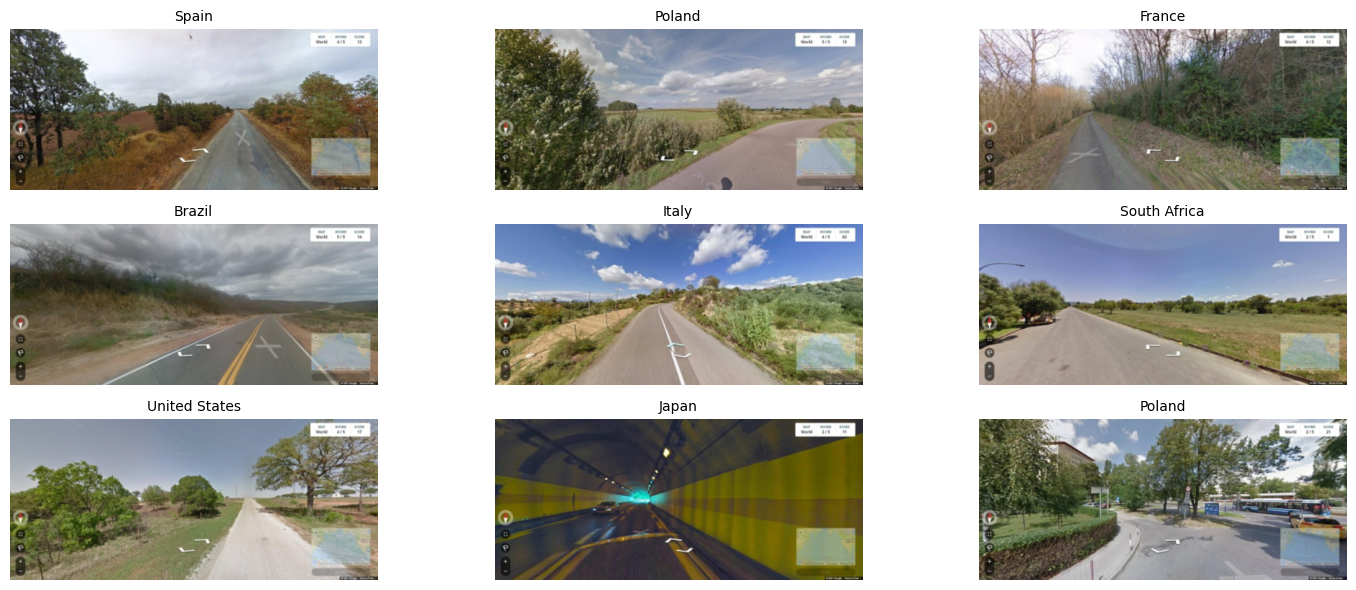

In [ ]:
def denormalize(img_tensor):
    mean = torch.tensor(CONFIG['mean']).view(3, 1, 1)
    std = torch.tensor(CONFIG['std']).view(3, 1, 1)
    return (img_tensor * std + mean).clamp(0, 1).permute(1, 2, 0).numpy()

g = torch.Generator().manual_seed(CONFIG['seed'])
images, labels = next(iter(DataLoader(image_ds['train'], batch_size=9, shuffle=True, generator=g)))
print('Batch shape:', tuple(images.shape))   # (batch, channels, height, width)

fig, axes = plt.subplots(3, 3, figsize=(15, 6))
for ax, img, lab in zip(axes.flat, images, labels):
    ax.imshow(denormalize(img))
    ax.set_title(CLASSES[lab], fontsize=10)
    ax.axis('off')
plt.tight_layout()
plt.show()

## Model: ResNet50 with a new head

We freeze every layer from the already pretrained ResNet with ImageNet, and we will replace the last layer with a new head.
The original ImageNet classification layer (2048 → 1000) is discarded, and the new head starts with randomly initialized weights.

The head will be configured with 2048 x 10 weights + 10 biases, 10 outputs (one per country).

In [ ]:
def build_model(num_classes=NUM_CLASSES):
    model = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V2)
    for p in model.parameters():
        p.requires_grad = False                                   # freeze the backbone
    model.fc = nn.Linear(model.fc.in_features, num_classes)       # new trainable head
    return model.to(device)

def count_params(model):
    total = sum(p.numel() for p in model.parameters())
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    return total, trainable

model = build_model()
total, trainable = count_params(model)
print(f'Total parameters: {total:,} | Trainable: {trainable:,} ({trainable / total * 100:.2f}%)')

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 209MB/s]


Total parameters: 23,528,522 | Trainable: 20,490 (0.09%)


## Feature extraction (computed once, cached in Drive)

The ResNet50 backbone is completely frozen; the weights won't change. However, the last head does need training. To avoid passing the images through the backbone in each epoch, we run every image once through the convolutional layers to extract and cache the 2,048-dimensional features.
We will temporarily replace the head `model.fc` with `nn.Identity`, turning the model into only a feature extractor. We will use `torch.inference_mode` and mixed precision to optimize the processing. Finally, we restore the original classification head, and we will save in cache the extracted tensors for train, validation, and test splits (saved in Drive for future head runs).


In [ ]:
@torch.inference_mode()
def extract_features(model, dataset, split_name):
    loader = DataLoader(dataset, shuffle=False, **loader_kwargs)
    head = model.fc
    model.fc = nn.Identity()          # the network now outputs the 2,048 features
    model.eval()
    feats, labs = [], []
    start = time.time()
    for i, (images, labels) in enumerate(loader, 1):
        with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=device.type == 'cuda'):
            f = model(images.to(device, non_blocking=True))
        feats.append(f.float().cpu())
        labs.append(labels)
        if i % 20 == 0 or i == len(loader):
            elapsed = time.time() - start
            print(f'  {split_name}: {i}/{len(loader)} batches | {elapsed / 60:.1f} min | '
                  f'~{elapsed / i * (len(loader) - i) / 60:.1f} min left')
    model.fc = head
    return torch.cat(feats), torch.cat(labs)

features = torch.load(FEATURES_PATH) if os.path.exists(FEATURES_PATH) else {}
for split in ['train', 'val', 'test']:
    if split in features:
        print(f'{split}: loaded from Drive {tuple(features[split][0].shape)}')
        continue
    features[split] = extract_features(model, image_ds[split], split)
    torch.save(features, FEATURES_PATH)
    print(f'{split}: extracted and saved {tuple(features[split][0].shape)}')

X_train, y_train = features['train']
X_val, y_val = features['val']
X_test, y_test = features['test']

  train: 20/151 batches | 8.7 min | ~56.8 min left
  train: 40/151 batches | 17.3 min | ~47.9 min left
  train: 60/151 batches | 25.9 min | ~39.3 min left
  train: 80/151 batches | 34.5 min | ~30.6 min left
  train: 100/151 batches | 43.0 min | ~21.9 min left
  train: 120/151 batches | 51.4 min | ~13.3 min left
  train: 140/151 batches | 59.9 min | ~4.7 min left
  train: 151/151 batches | 64.7 min | ~0.0 min left
train: extracted and saved (9661, 2048)
  val: 20/31 batches | 8.4 min | ~4.6 min left
  val: 31/31 batches | 12.6 min | ~0.0 min left
val: extracted and saved (1933, 2048)
  test: 20/31 batches | 8.5 min | ~4.7 min left
  test: 31/31 batches | 12.8 min | ~0.0 min left
test: extracted and saved (1933, 2048)


## Metric functions

* Macro F1-Score:

Assigns equal weight to all 10 classes to prevent class imbalance from biasing the evaluation. It combines Precision (minimizing false positives: how many times the predicted country was correct) and Recall (minimizing false negatives: how many of the actual country images were correctly captured). Averaging these metrics equitably ensures that minority countries are just as important as majority ones in our final score.

* Top-1 & Top-5 accuracy:

The model's final output is a probability distribution over the countries. For Top-1 accuracy, we select the country with the highest predicted probability and check if it matches the ground truth. For Top-5 accuracy, we apply the same logic but consider a prediction correct if the actual country is among the model's top 5 highest-probability guesses. This metric is especially valuable in geographic tasks to assess if the model groups visually similar regions together or places the correct country within its top candidate pool.

* ECE:

Calibration measures how reliable the model's confidence scores are. If the model predicts a group of images with 90% confidence, we expect it to be correct 90% of the time. ECE quantifies the overall gap between these predicted confidences and the actual accuracies, allowing us to detect if our model is overconfident (highly certain but wrong) or underconfident (uncertain but correct).


In [ ]:
def compute_metrics(probs, labels):
    preds = probs.argmax(axis=1)
    top5 = np.argsort(probs, axis=1)[:, -5:]
    return {
        'top1': (preds == labels).mean(),
        'top5': np.mean([lab in row for lab, row in zip(labels, top5)]),
        'f1_macro': f1_score(labels, preds, average='macro', zero_division=0),
    }

def expected_calibration_error(probs, labels, n_bins=15):
    conf = probs.max(axis=1)
    correct = probs.argmax(axis=1) == labels
    bins = np.linspace(0, 1, n_bins + 1)
    ece, bin_acc, bin_conf = 0.0, [], []
    for lo, hi in zip(bins[:-1], bins[1:]):
        in_bin = (conf > lo) & (conf <= hi)
        if in_bin.sum() > 0:
            acc, avg_conf = correct[in_bin].mean(), conf[in_bin].mean()
            ece += in_bin.mean() * abs(acc - avg_conf)
            bin_acc.append(acc)
            bin_conf.append(avg_conf)
    return ece, bin_acc, bin_conf

@torch.no_grad()
def head_predict(head, X, y, criterion):
    head.eval()
    logits = head(X.to(device))
    loss = criterion(logits, y.to(device)).item()
    return loss, torch.softmax(logits, dim=1).cpu().numpy(), y.numpy()

## Overfitting test (pipeline check)

Before the real training, we feed a tiny subset of 100 images into a temporary linear classifier (the probe) to verify if our training pipeline works correctly. Because the dataset is so small, a healthy model should easily memorize these images. A successful test is indicated by an intentional overfit where the training loss steadily decreases to near zero and accuracy reaches 100%. If the model fails to overfit, it alerts us that there is a silent bug somewhere in our data alignment, labels, or training loop logic.

In [ ]:
set_seed(CONFIG['seed'])
idx = torch.randperm(len(X_train))[:100]
X_small, y_small = X_train[idx].to(device), y_train[idx].to(device)

probe = nn.Linear(X_train.shape[1], NUM_CLASSES).to(device)
probe_opt = torch.optim.AdamW(probe.parameters(), lr=1e-2)
criterion = nn.CrossEntropyLoss()

for step in range(1, 201):
    probe.train()
    loss = criterion(probe(X_small), y_small)
    probe_opt.zero_grad()
    loss.backward()
    probe_opt.step()
    if step % 50 == 0:
        acc = (probe(X_small).argmax(1) == y_small).float().mean().item()
        print(f'Step {step:3d} | loss {loss.item():.3f} | train accuracy {acc:.2%}')

Step  50 | loss 0.022 | train accuracy 100.00%
Step 100 | loss 0.010 | train accuracy 100.00%
Step 150 | loss 0.007 | train accuracy 100.00%
Step 200 | loss 0.005 | train accuracy 100.00%


## Baseline training - Head, last layer only

Trains a simple linear classification head for 10 epochs using the pre-extracted semi-processed 2,048-dimensional features cached in Drive. By bypassing the forward pass of the deep convolutional ResNet50 backbone during training, each epoch executes almost instantly, making the process highly efficient.

During training, cached feature tensors are fed directly into the trainable linear head to optimize CPU or GPU cycles. The optimization process evaluates validation performance after each epoch, tracking metrics such as Top-1 Accuracy, Top-5 Accuracy, and Macro F1. Checkpointing retains the parameter weights corresponding to the epoch with the highest Validation Macro F1-Score (achieved at Epoch 10: 0.573). Finally, the complete model—including the frozen backbone and trained head weight states—along with config settings and alphabetical class indices, is saved to `plonknet10_baseline_v1.pt`, while raw metrics history is exported to `history_baseline_v1.csv`.


In [ ]:
set_seed(CONFIG['seed'])
head = nn.Linear(X_train.shape[1], NUM_CLASSES).to(device)
optimizer = torch.optim.AdamW(head.parameters(), lr=CONFIG['lr_head'], weight_decay=CONFIG['weight_decay'])
criterion = nn.CrossEntropyLoss()

g = torch.Generator().manual_seed(CONFIG['seed'])
train_loader_feats = DataLoader(TensorDataset(X_train, y_train), batch_size=CONFIG['batch_size'],
                                shuffle=True, generator=g)

history, best_f1, best_state, best_epoch = [], -1.0, None, None

for epoch in range(1, CONFIG['epochs'] + 1):
    start = time.time()
    head.train()
    total_loss = 0.0
    for xb, yb in train_loader_feats:
        xb, yb = xb.to(device), yb.to(device)
        loss = criterion(head(xb), yb)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * len(yb)

    _, tr_probs, tr_labels = head_predict(head, X_train, y_train, criterion)
    val_loss, va_probs, va_labels = head_predict(head, X_val, y_val, criterion)
    tr, va = compute_metrics(tr_probs, tr_labels), compute_metrics(va_probs, va_labels)

    history.append({'epoch': epoch, 'train_loss': total_loss / len(y_train), 'val_loss': val_loss,
                    'train_top1': tr['top1'], 'val_top1': va['top1'], 'val_top5': va['top5'],
                    'val_f1_macro': va['f1_macro'], 'seconds': time.time() - start})
    pd.DataFrame(history).to_csv(HISTORY_CSV, index=False)

    improved = va['f1_macro'] > best_f1
    if improved:
        best_f1, best_epoch, best_val = va['f1_macro'], epoch, va
        best_state = {k: v.detach().clone() for k, v in head.state_dict().items()}

    print(f"Epoch {epoch:2d} | train loss {history[-1]['train_loss']:.3f} | val loss {val_loss:.3f} | "
          f"train top-1 {tr['top1']:.2%} | val top-1 {va['top1']:.2%} | val top-5 {va['top5']:.2%} | "
          f"val F1 {va['f1_macro']:.3f}" + ('  <- best' if improved else ''))

# Put the best head back on the ResNet50 and save the complete model
head.load_state_dict(best_state)
model.fc.load_state_dict(best_state)
torch.save({
    'model_state': model.state_dict(),
    'classes': CLASSES,
    'config': CONFIG,
    'run_name': RUN_NAME,
    'epoch': best_epoch,
    'val_metrics': best_val,
}, CHECKPOINT_PATH)
print(f'\nBest epoch: {best_epoch} | validation macro F1: {best_f1:.3f}')
print('Checkpoint saved:', CHECKPOINT_PATH)

Epoch  1 | train loss 1.890 | val loss 1.704 | train top-1 47.44% | val top-1 45.73% | val top-5 87.22% | val F1 0.355  <- best
Epoch  2 | train loss 1.557 | val loss 1.534 | train top-1 53.09% | val top-1 50.59% | val top-5 89.96% | val F1 0.426  <- best
Epoch  3 | train loss 1.406 | val loss 1.433 | train top-1 58.54% | val top-1 53.70% | val top-5 92.03% | val F1 0.485  <- best
Epoch  4 | train loss 1.306 | val loss 1.376 | train top-1 59.81% | val top-1 55.10% | val top-5 92.65% | val F1 0.489  <- best
Epoch  5 | train loss 1.233 | val loss 1.327 | train top-1 63.04% | val top-1 56.96% | val top-5 93.53% | val F1 0.535  <- best
Epoch  6 | train loss 1.178 | val loss 1.285 | train top-1 64.01% | val top-1 59.03% | val top-5 93.74% | val F1 0.539  <- best
Epoch  7 | train loss 1.130 | val loss 1.255 | train top-1 65.58% | val top-1 59.86% | val top-5 93.95% | val F1 0.560  <- best
Epoch  8 | train loss 1.092 | val loss 1.234 | train top-1 66.77% | val top-1 60.89% | val top-5 94.57% 

## Learning curves

If the validation loss is still going down at the last epoch, the next run can use more epochs. If it goes up while the training loss keeps going down, the model is starting to overfit.

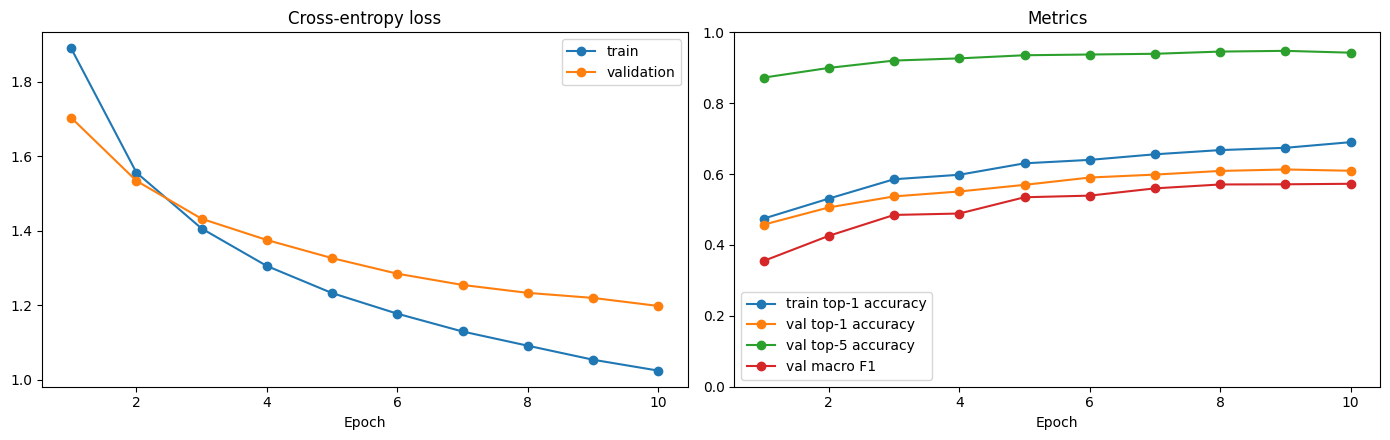

In [ ]:
hist = pd.DataFrame(history)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].plot(hist['epoch'], hist['train_loss'], marker='o', label='train')
axes[0].plot(hist['epoch'], hist['val_loss'], marker='o', label='validation')
axes[0].set_title('Cross-entropy loss')
axes[0].set_xlabel('Epoch')
axes[0].legend()

axes[1].plot(hist['epoch'], hist['train_top1'], marker='o', label='train top-1 accuracy')
axes[1].plot(hist['epoch'], hist['val_top1'], marker='o', label='val top-1 accuracy')
axes[1].plot(hist['epoch'], hist['val_top5'], marker='o', label='val top-5 accuracy')
axes[1].plot(hist['epoch'], hist['val_f1_macro'], marker='o', label='val macro F1')
axes[1].set_title('Metrics')
axes[1].set_xlabel('Epoch')
axes[1].set_ylim(0, 1)
axes[1].legend()

plt.tight_layout()
fig.savefig(f'{FIG_DIR}/p4_learning_curves_{RUN_NAME}.png', dpi=100)
plt.show()

Analyzing the training and validation progression, we can notice these points:

* **Loss gap and overfitting:** from epoch 3 onwards, a gap opens between the training and validation loss: the training loss keeps decreasing steadily, while the validation loss decreases more slowly. This is a moderate generalization gap (69% vs. 61% top-1 at epoch 10), but not harmful overfitting: the validation loss never goes up, and the best epoch is the last one. The head has not converged yet, so training for more epochs is the first adjustment to try.

* **Macro F1:** a uniform random guess gives about 10% top-1 and a macro F1 around 0.10, and always predicting the most frequent country gives about 15% top-1. Reaching a validation macro F1 of 0.573 and a top-1 accuracy of about 61% by training a single linear layer shows that ImageNet features already carry useful information for this task.

* **Top-5 accuracy:** the validation top-5 accuracy reaches about 94%. A random guess would give 50% with 10 classes, so this is well above chance; still, top-5 is a permissive metric with only 10 classes, which is why macro F1 is our primary metric.

## Detailed evaluation on validation

For the next adjustments, we run a thorough diagnostic on the validation set using the best performing classification head. Instead of relying solely on a single global metric, we dissect the model's behavior through multiple lenses.

* Per-country report: precision, recall and F1 for each country.
* F1 per group: easy vs. hard.
* Confusion matrix: which countries are confused with which (hypotheses 2, 3 and 5). Rows are the true country; each row sums to 100%.
* Reliability diagram and ECE: is the model's confidence equal to its real accuracy? (hypothesis 1)
* True vs. predicted share: does the model predict some countries more often than they appear? (hypothesis 1)

=== VAL ===
Loss 1.199 | top-1 60.94% | top-5 94.26% | macro F1 0.573 | ECE 0.085

               precision    recall  f1-score   support

       Brazil      0.599     0.673     0.633       284
       France      0.549     0.625     0.584       288
      Germany      0.798     0.650     0.717       103
        Italy      0.472     0.137     0.212       124
        Japan      0.651     0.812     0.722       287
       Poland      0.487     0.483     0.485       118
 South Africa      0.648     0.660     0.654       159
        Spain      0.446     0.365     0.401       170
     Thailand      0.685     0.565     0.619       131
United States      0.681     0.714     0.697       269

     accuracy                          0.609      1933
    macro avg      0.602     0.568     0.573      1933
 weighted avg      0.603     0.609     0.597      1933

Mean F1 per group:
group
easy    0.665
hard    0.480
Name: f1, dtype: float64


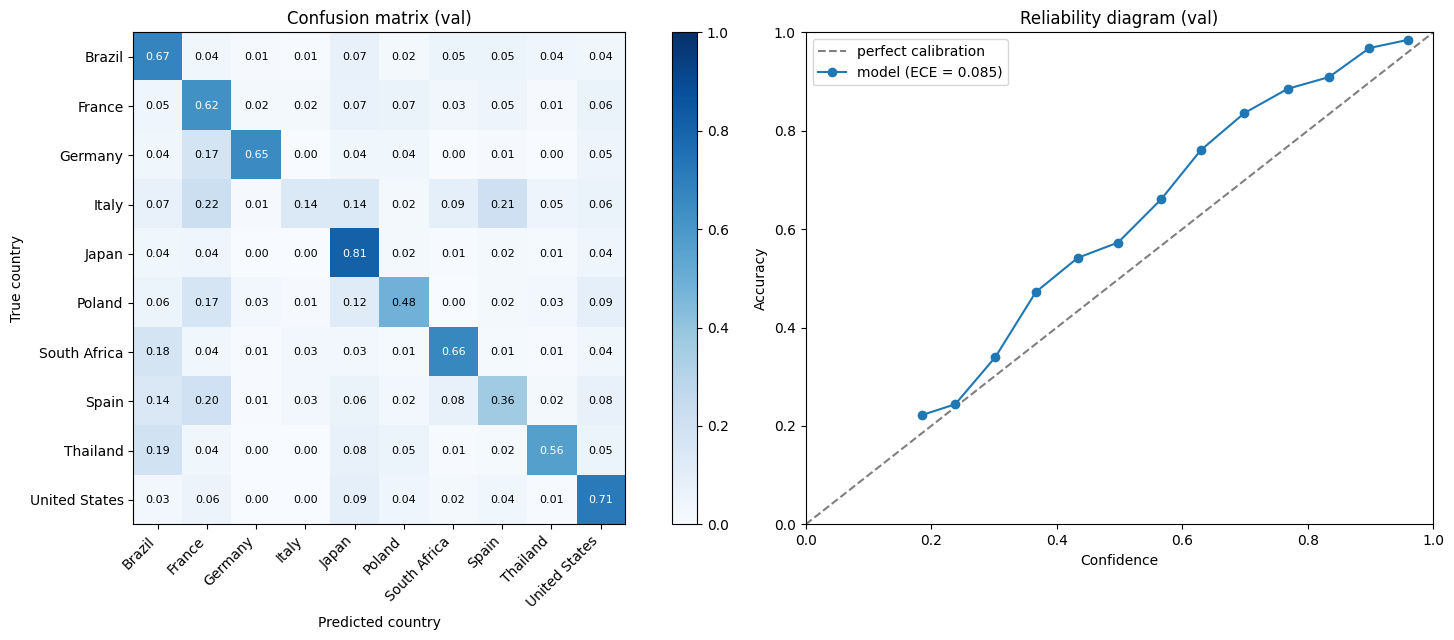


True vs. predicted share per country:
               true_share  predicted_share
Brazil              0.147            0.165
France              0.149            0.170
Germany             0.053            0.043
Italy               0.064            0.019
Japan               0.148            0.185
Poland              0.061            0.061
South Africa        0.082            0.084
Spain               0.088            0.072
Thailand            0.068            0.056
United States       0.139            0.146


In [ ]:
def full_report(X, y, split_name):
    loss, probs, labels = head_predict(head, X, y, criterion)
    preds = probs.argmax(axis=1)
    m = compute_metrics(probs, labels)
    ece, bin_acc, bin_conf = expected_calibration_error(probs, labels)

    print(f'=== {split_name.upper()} ===')
    print(f"Loss {loss:.3f} | top-1 {m['top1']:.2%} | top-5 {m['top5']:.2%} | macro F1 {m['f1_macro']:.3f} | ECE {ece:.3f}\n")
    print(classification_report(labels, preds, target_names=CLASSES, digits=3, zero_division=0))

    # F1 per group
    f1_df = pd.DataFrame({'country': CLASSES, 'f1': f1_score(labels, preds, average=None, zero_division=0)})
    f1_df['group'] = f1_df['country'].apply(lambda c: 'easy' if c in EASY else 'hard')
    print('Mean F1 per group:')
    print(f1_df.groupby('group')['f1'].mean().round(3))

    # Confusion matrix (row-normalized) + reliability diagram
    cm = confusion_matrix(labels, preds, normalize='true')
    fig, axes = plt.subplots(1, 2, figsize=(17, 6.5), gridspec_kw={'width_ratios': [1.5, 1]})
    im = axes[0].imshow(cm, cmap='Blues', vmin=0, vmax=1)
    axes[0].set_xticks(range(NUM_CLASSES))
    axes[0].set_xticklabels(CLASSES, rotation=45, ha='right')
    axes[0].set_yticks(range(NUM_CLASSES))
    axes[0].set_yticklabels(CLASSES)
    for i in range(NUM_CLASSES):
        for j in range(NUM_CLASSES):
            axes[0].text(j, i, f'{cm[i, j]:.2f}', ha='center', va='center', fontsize=8,
                         color='white' if cm[i, j] > 0.5 else 'black')
    axes[0].set_xlabel('Predicted country')
    axes[0].set_ylabel('True country')
    axes[0].set_title(f'Confusion matrix ({split_name})')
    fig.colorbar(im, ax=axes[0], fraction=0.046)

    axes[1].plot([0, 1], [0, 1], linestyle='--', color='gray', label='perfect calibration')
    axes[1].plot(bin_conf, bin_acc, marker='o', label=f'model (ECE = {ece:.3f})')
    axes[1].set_xlabel('Confidence')
    axes[1].set_ylabel('Accuracy')
    axes[1].set_title(f'Reliability diagram ({split_name})')
    axes[1].set_xlim(0, 1)
    axes[1].set_ylim(0, 1)
    axes[1].legend()

    plt.tight_layout()
    fig.savefig(f'{FIG_DIR}/p4_eval_{split_name}_{RUN_NAME}.png', dpi=100)
    plt.show()

    share = pd.DataFrame({
        'true_share': pd.Series(labels).value_counts(normalize=True).reindex(range(NUM_CLASSES), fill_value=0).values,
        'predicted_share': pd.Series(preds).value_counts(normalize=True).reindex(range(NUM_CLASSES), fill_value=0).values,
    }, index=CLASSES).round(3)
    print('\nTrue vs. predicted share per country:')
    print(share)
    return {'loss': loss, **m, 'ece': ece}

val_results = full_report(X_val, y_val, 'val')

### Validation results interpretation

* **Easy vs. hard groups:** there is a clear performance gap between the groups. The easy countries reach an average **F1 of 0.665** (led by Japan and the United States), while the hard countries drop to **0.480**.
* **France as a "sink":** France attracts errors from the rest of Europe: 17–22% of the images from Germany, Italy, Poland and Spain are predicted as France, which lowers its precision (0.549).
* **Over-prediction of large classes:** the countries with the most images are predicted more often than they appear, for example Japan (18.5% of predictions vs. 14.8% of images) and France (17.0% vs. 14.9%), as expected in hypothesis 1.
* **Italy as the worst performer:** Italy is the bottleneck of this baseline, with an **F1 of 0.212**. Only 14% of the Italian images are recognized; the rest go mainly to France (22%), Spain (21%) and, surprisingly, Japan (14%).
* **Germany as a surprise:** despite being the smallest class (491 training images), Germany reaches an F1 of 0.717 and the highest precision (0.798).
* **Underconfidence:** the reliability diagram stays *above* the diagonal (ECE = 0.085): the model is right more often than its confidence says. This is the opposite of hypothesis 1, and temperature scaling can correct it.

## Final evaluation on test

The test set has not been used for any decision. This is the result that is reported for the baseline.

=== TEST ===
Loss 1.140 | top-1 62.60% | top-5 94.72% | macro F1 0.585 | ECE 0.102

               precision    recall  f1-score   support

       Brazil      0.692     0.711     0.701       304
       France      0.508     0.628     0.561       269
      Germany      0.807     0.710     0.755       100
        Italy      0.520     0.113     0.186       115
        Japan      0.673     0.798     0.730       302
       Poland      0.589     0.438     0.502       128
 South Africa      0.692     0.718     0.705       163
        Spain      0.431     0.413     0.422       150
     Thailand      0.618     0.633     0.626       120
United States      0.661     0.670     0.665       282

     accuracy                          0.626      1933
    macro avg      0.619     0.583     0.585      1933
 weighted avg      0.623     0.626     0.614      1933

Mean F1 per group:
group
easy    0.685
hard    0.485
Name: f1, dtype: float64


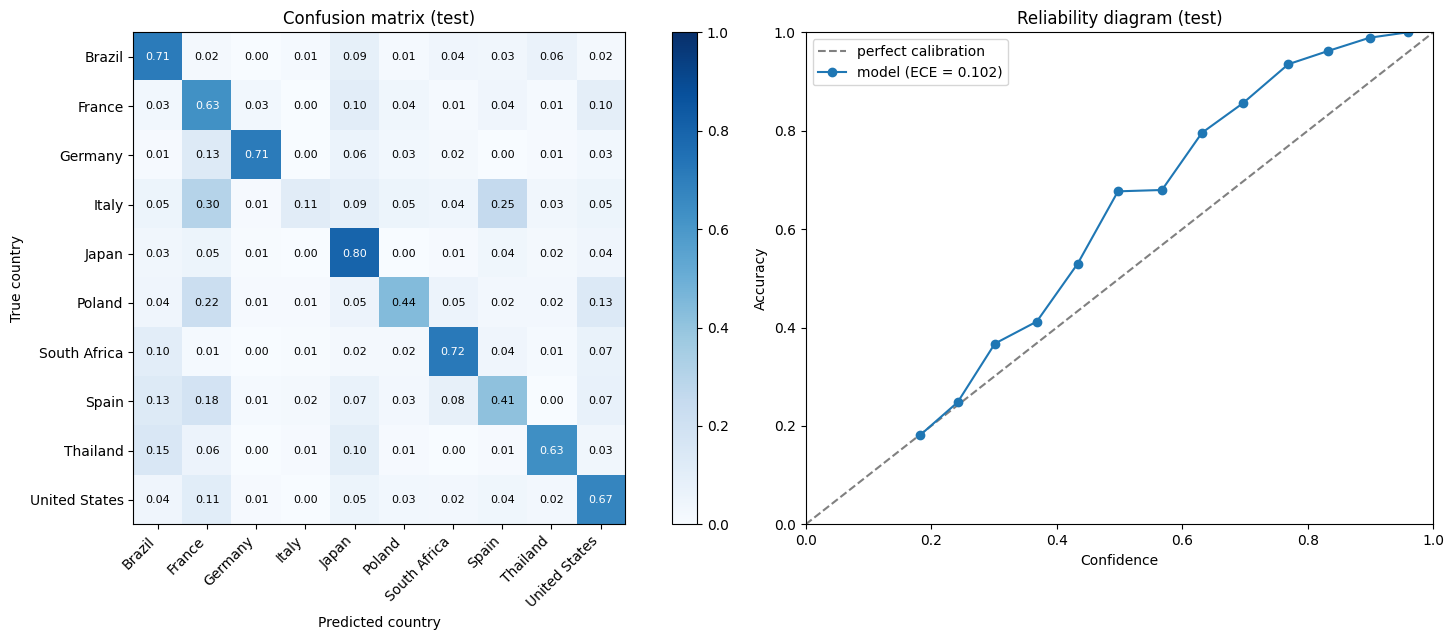


True vs. predicted share per country:
               true_share  predicted_share
Brazil              0.157            0.161
France              0.139            0.172
Germany             0.052            0.046
Italy               0.059            0.013
Japan               0.156            0.185
Poland              0.066            0.049
South Africa        0.084            0.087
Spain               0.078            0.074
Thailand            0.062            0.064
United States       0.146            0.148
           run split    loss    top1    top5  f1_macro     ece
0  baseline_v1   val  1.1985  0.6094  0.9426    0.5726  0.0846
1  baseline_v1  test  1.1400  0.6260  0.9472    0.5854  0.1018


In [ ]:
test_results = full_report(X_test, y_test, 'test')

summary = pd.DataFrame([{'run': RUN_NAME, 'split': 'val', **val_results},
                        {'run': RUN_NAME, 'split': 'test', **test_results}]).round(4)
summary.to_csv(RESULTS_CSV, index=False)
print(summary)

## Optional adjustment: fine-tuning the convolutional blocks

**Note, not run yet.**


Instead of keeping the entire ResNet50 frozen and relying on static cached features (which were optimized for generic ImageNet objects), we unfreeze the final residual block (`layer4`).

By unfreezing this section, the internal convolutional filters can update their weights to dynamically adjust to the unique visual cues of Street View (such as soil tone, specific utility poles, or road line colors). Because the feature extractor itself changes with each backpropagation step, we can no longer use our cached tensors—every image must pass through the entire network in every epoch. This demands a GPU to run efficiently, but theoretically offers the model much higher flexibility to specialize in geographical nuances.

In [ ]:
RUN_FINETUNE = False

def set_train_mode(model):
    model.train()
    for m in model.modules():
        if isinstance(m, nn.BatchNorm2d) and not any(p.requires_grad for p in m.parameters()):
            m.eval()

def run_epoch(model, loader, criterion, optimizer=None, scaler=None):
    training = optimizer is not None
    if training:
        set_train_mode(model)
    else:
        model.eval()
    total_loss, all_probs, all_labels = 0.0, [], []
    with torch.set_grad_enabled(training):
        for images, labels in loader:
            images, labels = images.to(device, non_blocking=True), labels.to(device, non_blocking=True)
            with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=device.type == 'cuda'):
                logits = model(images)
                loss = criterion(logits, labels)
            if training:
                optimizer.zero_grad(set_to_none=True)
                scaler.scale(loss).backward()
                scaler.step(optimizer)
                scaler.update()
            total_loss += loss.item() * images.size(0)
            all_probs.append(torch.softmax(logits.float(), dim=1).detach().cpu())
            all_labels.append(labels.cpu())
    return total_loss / len(loader.dataset), torch.cat(all_probs).numpy(), torch.cat(all_labels).numpy()

if RUN_FINETUNE:
    assert device.type == 'cuda', 'Fine-tuning needs a GPU'
    FT_RUN_NAME = 'finetune_v2'
    FT_CHECKPOINT = f'{MODEL_DIR}/plonknet10_{FT_RUN_NAME}.pt'
    FT_HISTORY = f'{OUT_DIR}/history_{FT_RUN_NAME}.csv'
    FT_EPOCHS, LR_BACKBONE = 5, 1e-4

    # Start from the best baseline weights and unfreeze layer4
    model.load_state_dict(torch.load(CHECKPOINT_PATH, map_location=device, weights_only=False)['model_state'])
    for p in model.layer4.parameters():
        p.requires_grad = True
    for p in model.fc.parameters():
        p.requires_grad = True
    print('Trainable parameters:', f'{count_params(model)[1]:,}')

    g = torch.Generator().manual_seed(CONFIG['seed'])
    ft_train_loader = DataLoader(image_ds['train'], shuffle=True, generator=g, **loader_kwargs)
    ft_val_loader = DataLoader(image_ds['val'], shuffle=False, **loader_kwargs)
    ft_optimizer = torch.optim.AdamW([
        {'params': model.layer4.parameters(), 'lr': LR_BACKBONE},
        {'params': model.fc.parameters(), 'lr': CONFIG['lr_head']},
    ], weight_decay=CONFIG['weight_decay'])
    ft_scaler = torch.amp.GradScaler(enabled=device.type == 'cuda')

    ft_history, ft_best = [], -1.0
    for epoch in range(1, FT_EPOCHS + 1):
        start = time.time()
        train_loss, _, _ = run_epoch(model, ft_train_loader, criterion, ft_optimizer, ft_scaler)
        val_loss, va_probs, va_labels = run_epoch(model, ft_val_loader, criterion)
        va = compute_metrics(va_probs, va_labels)
        ft_history.append({'epoch': epoch, 'train_loss': train_loss, 'val_loss': val_loss,
                           'val_top1': va['top1'], 'val_top5': va['top5'], 'val_f1_macro': va['f1_macro']})
        pd.DataFrame(ft_history).to_csv(FT_HISTORY, index=False)
        improved = va['f1_macro'] > ft_best
        if improved:
            ft_best = va['f1_macro']
            torch.save({'model_state': model.state_dict(), 'classes': CLASSES, 'config': CONFIG,
                        'run_name': FT_RUN_NAME, 'epoch': epoch, 'val_metrics': va}, FT_CHECKPOINT)
        print(f"Epoch {epoch} | val loss {val_loss:.3f} | val top-1 {va['top1']:.2%} | "
              f"val F1 {va['f1_macro']:.3f} | {time.time() - start:.0f}s" + ('  <- best, saved' if improved else ''))
    print(f'\nBest fine-tuning macro F1 on validation: {ft_best:.3f} (baseline: {best_f1:.3f})')
else:
    print('Fine-tuning skipped (RUN_FINETUNE = False).')

Fine-tuning skipped (RUN_FINETUNE = False).


## Final check: outputs in Drive

In [ ]:
for f in [FEATURES_PATH, CHECKPOINT_PATH, HISTORY_CSV, RESULTS_CSV,
          f'{FIG_DIR}/p4_learning_curves_{RUN_NAME}.png', f'{FIG_DIR}/p4_eval_val_{RUN_NAME}.png',
          f'{FIG_DIR}/p4_eval_test_{RUN_NAME}.png']:
    size = f' ({os.path.getsize(f) / 1e6:.1f} MB)' if os.path.exists(f) else ''
    print(('OK       ' if os.path.exists(f) else 'MISSING  ') + f + size)

OK       /content/drive/MyDrive/IAconcentrada/GEOGUSSR/Outputs/features_resnet50_224x512.pt (110.9 MB)
OK       /content/drive/MyDrive/IAconcentrada/GEOGUSSR/Outputs/models/plonknet10_baseline_v1.pt (94.4 MB)
OK       /content/drive/MyDrive/IAconcentrada/GEOGUSSR/Outputs/history_baseline_v1.csv (0.0 MB)
OK       /content/drive/MyDrive/IAconcentrada/GEOGUSSR/Outputs/results_baseline_v1.csv (0.0 MB)
OK       /content/drive/MyDrive/IAconcentrada/GEOGUSSR/Outputs/figures/p4_learning_curves_baseline_v1.png (0.1 MB)
OK       /content/drive/MyDrive/IAconcentrada/GEOGUSSR/Outputs/figures/p4_eval_val_baseline_v1.png (0.1 MB)
OK       /content/drive/MyDrive/IAconcentrada/GEOGUSSR/Outputs/figures/p4_eval_test_baseline_v1.png (0.1 MB)


### Google Drive Outputs Summary

* **`features_resnet50_224x512.pt`:**

Cached 2048-D image features extracted via the frozen ResNet50 backbone to accelerate head-only training.
* **`plonknet10_baseline_v1.pt`:**

Final model checkpoint saving architecture parameters, best-epoch head weights, training configuration, and class indices.
* **`history_baseline_v1.csv`:**

Epoch-by-epoch training and validation loss and accuracy metrics.
* **`results_baseline_v1.csv`:**

Final performance comparison metrics between the validation and test datasets.
* **Figures (`.png` files):**

Plots documenting loss/metric learning curves, confusion matrices, and reliability/calibration diagrams for both validation and test splits.